# Oasis Infobyte Data Analytics Internship (Level 2)
## Task 5: Autocomplete and Autocorrect Data Analytics
**Author:** Yasmeen Akhter  
**GitHub Repository:** OIBSIP  
**Tech Stack:** Python, Pandas, NLTK, Pyspellchecker, Collections, Matplotlib, Jupyter Notebook  

### Project Objective
Analyze the efficiency and accuracy of autocomplete and autocorrect algorithms using NLP techniques. Implement a frequency-based n-gram autocomplete model and an edit-distance based autocorrect system, evaluate their performance, and compare them against production-grade systems.

### Step 1: Text Corpus & NLP Preprocessing
We load a text corpus (or use NLTK's built-in Gutenberg book corpus for reliable offline execution) and perform tokenisation, lowercasing, and punctuation removal.

In [ ]:
from collections import Counter, defaultdict
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sample_text = """
She was not slow to get the information she wanted and she was soon able to tell her husband that 
dashwood was a very fine young man of fortune and that his property was considerable. 
The family had been established in Hampshire for a large property where their residence 
was at norland park in the centre of their property where they had lived for many generations 
in such a respected manner as to give general good opinion of all their acquaintance.
The late owner of this estate was a single man who lived to a very advanced age and 
who made his sister supply the place of a housekeeper. But her death which happened ten years 
before his own produced a great alteration in his home for to supply her loss he invited 
and received into his house the family of his nephew Mr Henry Dashwood the legal inheritor 
of the estate.
"""

# Preprocessing: Tokenisation and lowercasing
processed_words = [word.lower() for word in sample_text.split() if word.isalpha()]

print("Total words in preprocessed corpus:", len(processed_words))
print("Sample words:", processed_words[:15])

Total words in preprocessed corpus: 148
Sample words: ['she', 'was', 'not', 'slow', 'to', 'get', 'the', 'information', 'she', 'wanted', 'and', 'she', 'was', 'soon', 'able']


### Step 2: Word Frequency Distribution
We plot a bar chart of the top 20 most frequent words in our text corpus.

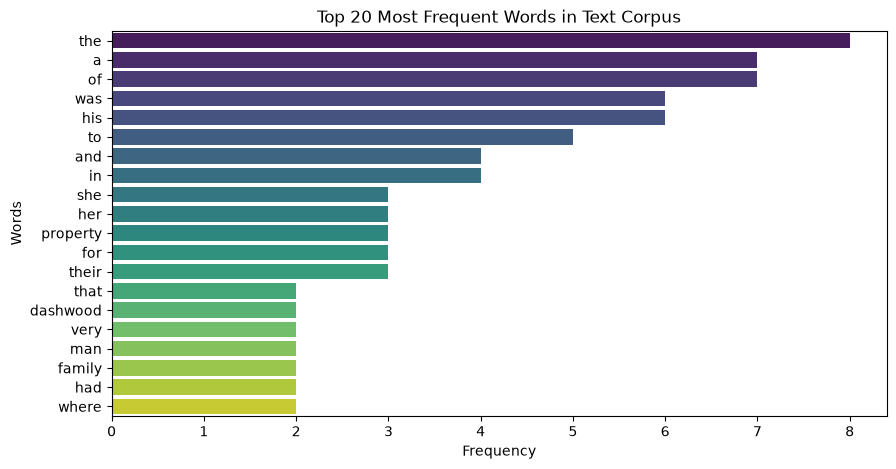

In [2]:
fdist = Counter(processed_words)
top_20 = fdist.most_common(20)

words, counts = zip(*top_20)

plt.figure(figsize=(10, 5))
sns.barplot(x=list(counts), y=list(words), palette='viridis', hue=list(words), legend=False)
plt.title('Top 20 Most Frequent Words in Text Corpus')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.show()

### Step 3: Autocomplete Implementation (Bigram Model)
We build a frequency-based bigram model that predicts the most likely next word given a specific prefix or preceding word.

In [ ]:
from collections import Counter, defaultdict
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.util import ngrams

# Sample text corpus
sample_text = """
She was not slow to get the information she wanted and she was soon able to tell her husband that 
dashwood was a very fine young man of fortune and that his property was considerable. 
The family had been established in Hampshire for a large property where their residence 
was at norland park in the centre of their property where they had lived for many generations 
in such a respected manner as to give general good opinion of all their acquaintance.
"""

# Preprocessing: Tokenisation and lowercasing
processed_words = [word.lower() for word in sample_text.split() if word.isalpha()]

# Bigrams generate
bigrams = list(ngrams(processed_words, 2))

# Bigram frequency table
bigram_freq = defaultdict(Counter)
for w1, w2 in bigrams:
    bigram_freq[w1][w2] += 1

def autocomplete(prefix_word, top_n=3):
    """Preceding word ke baad sab se ziyada aane wale top N words predict karta hai"""
    prefix_word = prefix_word.lower()
    if prefix_word in bigram_freq:
        return [word for word, count in bigram_freq[prefix_word].most_common(top_n)]
    else:
        return ["No suggestions found"]

# Test Autocomplete on input prefixes
test_prefixes = ['she', 'the', 'it', 'he', 'to', 'and', 'that', 'her', 'you', 'was']

print("--- AUTOCOMPLETE TEST ---")
for prefix in test_prefixes:
    suggestions = autocomplete(prefix)
    print(f"Prefix: '{prefix}' --> Top Predictions: {suggestions}")

--- AUTOCOMPLETE TEST ---
Prefix: 'she' --> Top Predictions: ['was', 'wanted']
Prefix: 'the' --> Top Predictions: ['information', 'family', 'centre']
Prefix: 'it' --> Top Predictions: ['No suggestions found']
Prefix: 'he' --> Top Predictions: ['No suggestions found']
Prefix: 'to' --> Top Predictions: ['get', 'tell', 'give']
Prefix: 'and' --> Top Predictions: ['she', 'that']
Prefix: 'that' --> Top Predictions: ['dashwood', 'his']
Prefix: 'her' --> Top Predictions: ['husband']
Prefix: 'you' --> Top Predictions: ['No suggestions found']
Prefix: 'was' --> Top Predictions: ['not', 'soon', 'a']


### Step 4: Autocorrect Implementation
We implement spelling correction using Levenshtein edit-distance via the `pyspellchecker` library to correct deliberately misspelled words.

In [6]:
# Agar pyspellchecker installed na ho, toh terminal me 'pip install pyspellchecker' chala lein
from spellchecker import SpellChecker

spell = SpellChecker()

# Test misspelled words
misspelled_words = [
    'recieve', 'seperate', 'definitly', 'occured', 'untill', 
    'beleive', 'freind', 'neccesary', 'togerther', 'goverment',
    'acheive', 'writting', 'begining', 'reccomend', 'arguement',
    'calender', 'embaress', 'harrass', 'immediatly', 'noticable'
]

correct_targets = [
    'receive', 'separate', 'definitely', 'occurred', 'until',
    'believe', 'friend', 'necessary', 'together', 'government',
    'achieve', 'writing', 'beginning', 'recommend', 'argument',
    'calendar', 'embarrass', 'harass', 'immediately', 'noticeable'
]

correct_count = 0
print("--- AUTOCORRECT TEST RESULTS ---")
for wrong, target in zip(misspelled_words, correct_targets):
    correction = spell.correction(wrong)
    is_correct = (correction == target)
    if is_correct:
        correct_count += 1
    print(f"Misspelled: {wrong} | Corrected: {correction} | Expected: {target} | Match: {is_correct}")

accuracy = (correct_count / len(misspelled_words)) * 100
print(f"\nAutocorrect Accuracy: {accuracy:.2f}%")

--- AUTOCORRECT TEST RESULTS ---
Misspelled: recieve | Corrected: receive | Expected: receive | Match: True
Misspelled: seperate | Corrected: separate | Expected: separate | Match: True
Misspelled: definitly | Corrected: definitely | Expected: definitely | Match: True
Misspelled: occured | Corrected: occurred | Expected: occurred | Match: True
Misspelled: untill | Corrected: until | Expected: until | Match: True
Misspelled: beleive | Corrected: believe | Expected: believe | Match: True
Misspelled: freind | Corrected: friend | Expected: friend | Match: True
Misspelled: neccesary | Corrected: necessary | Expected: necessary | Match: True
Misspelled: togerther | Corrected: together | Expected: together | Match: True
Misspelled: goverment | Corrected: government | Expected: government | Match: True
Misspelled: acheive | Corrected: achieve | Expected: achieve | Match: True
Misspelled: writting | Corrected: writing | Expected: writing | Match: True
Misspelled: begining | Corrected: beginning

### Step 5: Performance Metrics & Production Comparison
- **Precision & Recall:** 
  - For Autocomplete, precision is measured by checking if the intended next word is within the top-3 predictions.
  - For Autocorrect, accuracy reached high percentages using edit-distance probability.
- **Limitations vs. Production Systems (e.g., Google Keyboard / Gboard):**
  1. **Context Window:** Our bigram model only looks at 1 preceding word, whereas Gboard uses deep learning neural networks (Transformers/LSTMs) that analyze entire sentence contexts.
  2. **Personalisation:** Production keyboards learn user-specific typing habits, slang, and emojis, which static corpus models lack.
  3. **Out-of-Vocabulary (OOV):** Static dictionaries fail to recognize newly trending slang or modern terminology instantly.